# 02 — Preprocessing & Modeling

### Prediksi Risiko Dropout Mahasiswa pada Awal Semester 2

Notebook ini melanjutkan `01_eda.ipynb` dan mencakup:

1. Feature engineering yang beralasan
2. Pembagian data train/test yang benar
3. Pipeline preprocessing
4. Perbandingan **3 algoritma**: Logistic Regression, Random Forest, XGBoost
5. Hyperparameter tuning dengan RandomizedSearchCV
6. Evaluasi pada holdout test
7. Threshold tuning
8. Confusion matrix, ROC, dan Precision-Recall
9. Feature importance
10. Analisis kesalahan dan overfitting
11. Penyimpanan model untuk aplikasi Streamlit

> **Estimasi runtime:** 10–15 menit, karena menjalankan 5-fold cross-validation dan hyperparameter tuning pada 100.000 baris.

## 0. Setup

`RANDOM_STATE = 42` dipakai konsisten agar split, CV, dan tuning reproducible.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import joblib

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate,
    RandomizedSearchCV, cross_val_predict,
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay,
    roc_curve, precision_recall_curve,
)
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

RANDOM_STATE = 42

DATA = Path("../data/student_dropout_risk_2026.csv")
if not DATA.exists():
    DATA = Path("data/student_dropout_risk_2026.csv")

df = pd.read_csv(DATA)
print("Shape:", df.shape)

Shape: (100000, 34)


## 1. Persiapan Fitur

Berdasarkan temuan EDA, ada tiga kelompok kolom yang harus ditangani:

| Keputusan | Kolom | Alasan |
|---|---|---|
| Dibuang | `person_id` | Identifier, tidak prediktif |
| Dibuang | `gpa_semester_2` | **Leakage** — belum tersedia di awal semester 2 |
| Dibuang | `semester` | Tidak konsisten dengan skenario awal semester 2 |
| Diganti | `units_passed` | Redundan: `passed = enrolled − failed` |
| Ditambah | `fail_rate` | Rasio mata kuliah gagal, lebih informatif daripada jumlah mentah |
| Ditambah | `engagement_score` | Rata-rata kehadiran & pengumpulan tugas |
| Ditambah | `risk_flag_count` | Jumlah indikator risiko (0–4) berdasarkan ambang dari EDA |

`risk_flag_count` memakai ambang yang punya makna domain, bukan hasil optimasi pada data test:

- `units_failed >= 3`
- `attendance_rate < 70`
- `missed_deadlines > 2`
- `gpa_semester_1 < 2`

In [2]:
df_model = df.copy()

df_model = df_model.drop(columns=["person_id", "gpa_semester_2", "semester"])

# Feature engineering
df_model["fail_rate"] = df_model["units_failed"] / df_model["units_enrolled"]
df_model["engagement_score"] = (
    df_model["attendance_rate"] + df_model["assignments_submitted_rate"]
) / 2
df_model["risk_flag_count"] = (
    (df_model["units_failed"] >= 3).astype(int)
    + (df_model["attendance_rate"] < 70).astype(int)
    + (df_model["missed_deadlines"] > 2).astype(int)
    + (df_model["gpa_semester_1"] < 2).astype(int)
)

# units_passed sudah terwakili oleh units_enrolled, units_failed, dan fail_rate
df_model = df_model.drop(columns=["units_passed"])

print("Shape setelah persiapan:", df_model.shape)
display(df_model[[
    "units_enrolled", "units_failed", "fail_rate",
    "attendance_rate", "assignments_submitted_rate",
    "engagement_score", "risk_flag_count", "dropout",
]].head())

Shape setelah persiapan: (100000, 33)


,units_enrolled,units_failed,fail_rate,attendance_rate,assignments_submitted_rate,engagement_score,risk_flag_count,dropout
0,11,0,0.000000,77.3,75.0,76.15,1,0
1,14,3,0.214286,52.1,80.1,66.10,2,1
2,17,3,0.176471,100.0,67.8,83.90,1,0
3,13,2,0.153846,83.9,100.0,91.95,0,0
4,8,1,0.125000,61.6,100.0,80.80,1,0


In [3]:
X = df_model.drop(columns=["dropout"])
y = df_model["dropout"]

print("Jumlah fitur:", X.shape[1])
print("\nFitur numerik:")
print(list(X.select_dtypes("number").columns))
print("\nFitur kategorikal:")
print(list(X.select_dtypes(exclude="number").columns))
print("\nDistribusi target:")
print(y.value_counts(normalize=True).round(3).to_string())

Jumlah fitur: 32

Fitur numerik:
['age', 'first_generation', 'disability_status', 'scholarship_holder', 'tuition_up_to_date', 'part_time_job', 'weekly_work_hours', 'international_student', 'admission_grade', 'previous_qualification_grade', 'units_enrolled', 'units_failed', 'gpa_semester_1', 'attendance_rate', 'assignments_submitted_rate', 'library_visits_per_month', 'lms_logins_per_week', 'extracurricular_activities', 'missed_deadlines', 'stress_level', 'mental_health_support', 'satisfaction_score', 'commute_time_mins', 'sleep_hours', 'fail_rate', 'engagement_score', 'risk_flag_count']

Fitur kategorikal:
['gender', 'nationality', 'family_income_level', 'course_type', 'study_mode']

Distribusi target:
dropout
0    0.68
1    0.32


## 2. Pembagian Data Train dan Test

Split dilakukan **sebelum** preprocessing dan tuning apa pun agar data test tidak pernah terlihat selama proses training. Rasio **80:20** dengan **stratifikasi** menjaga proporsi kelas tetap sama di kedua subset.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

print(f"Train : {X_train.shape[0]:,} baris x {X_train.shape[1]} fitur")
print(f"Test  : {X_test.shape[0]:,} baris x {X_test.shape[1]} fitur")
print()
print(f"Proporsi dropout di train : {y_train.mean():.4f}")
print(f"Proporsi dropout di test  : {y_test.mean():.4f}")

Train : 80,000 baris x 32 fitur
Test  : 20,000 baris x 32 fitur

Proporsi dropout di train : 0.3200
Proporsi dropout di test  : 0.3201


**Interpretasi.** Proporsi dropout di train dan test sama (32,0%), sehingga stratifikasi berhasil. Data test disimpan terpisah dan **baru digunakan pada bagian evaluasi akhir** — tidak dipakai untuk memilih fitur, tuning, atau threshold.

## 3. Pipeline Preprocessing

Preprocessing dibungkus dalam `Pipeline` supaya:

- Transformasi hanya di-fit pada data training (mencegah leakage),
- Konfigurasi yang sama otomatis dipakai saat prediksi di aplikasi,
- Cross-validation memperlakukan preprocessing sebagai bagian dari model.

**Strategi per tipe fitur:**

| Kelompok | Perlakuan | Alasan |
|---|---|---|
| Numerik miring (skew > 1, non-biner) | `log1p` + `StandardScaler` | Meredam ekor panjang, membantu model linear |
| Numerik lainnya | `StandardScaler` | Menyamakan skala untuk Logistic Regression |
| Kategorikal | `OneHotEncoder(handle_unknown="ignore")` | Model membutuhkan angka; kategori baru di aplikasi tidak error |

**Yang sengaja tidak dilakukan:**

- **Imputasi** — tidak ada missing value.
- **SMOTE** — kelas 68:32 masih wajar; `class_weight`/`scale_pos_weight` lebih sederhana dan tidak menambah risiko overfitting sintetis.
- **Penghapusan outlier** — outlier masih wajar secara domain dan berpotensi menjadi sinyal risiko.

In [5]:
numeric_features = list(X_train.select_dtypes("number").columns)
categorical_features = [c for c in X_train.columns if c not in numeric_features]

# log1p hanya untuk fitur kontinu yang miring; fitur biner (0/1) dikecualikan
skewed_features = [
    c for c in numeric_features
    if X_train[c].nunique() > 2 and X_train[c].skew() > 1
]
other_numeric = [c for c in numeric_features if c not in skewed_features]

print("Fitur miring (log1p + scale):", skewed_features)
print("Fitur numerik lain (scale)  :", len(other_numeric), "kolom")
print("Fitur kategorikal (one-hot) :", categorical_features)


def buat_preprocessor():
    return ColumnTransformer(
        transformers=[
            ("skewed", Pipeline([
                ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                ("scale", StandardScaler()),
            ]), skewed_features),
            ("numeric", StandardScaler(), other_numeric),
            ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ],
        remainder="drop",
    )


def buat_pipeline(model):
    return Pipeline([
        ("prep", buat_preprocessor()),
        ("model", model),
    ])

Fitur miring (log1p + scale): ['library_visits_per_month', 'missed_deadlines', 'commute_time_mins']
Fitur numerik lain (scale)  : 24 kolom
Fitur kategorikal (one-hot) : ['gender', 'nationality', 'family_income_level', 'course_type', 'study_mode']


In [6]:
# Cek bentuk hasil transformasi (fit hanya pada train)
prep_cek = buat_preprocessor()
X_train_cek = prep_cek.fit_transform(X_train)
nama_fitur = prep_cek.get_feature_names_out()

print("Shape setelah preprocessing:", X_train_cek.shape)
print("Jumlah fitur hasil transformasi:", len(nama_fitur))
print("\nContoh 15 nama fitur:")
for f in nama_fitur[:15]:
    print(" -", f)

Shape setelah preprocessing: (80000, 56)
Jumlah fitur hasil transformasi: 56

Contoh 15 nama fitur:
 - skewed__library_visits_per_month
 - skewed__missed_deadlines
 - skewed__commute_time_mins
 - numeric__age
 - numeric__first_generation
 - numeric__disability_status
 - numeric__scholarship_holder
 - numeric__tuition_up_to_date
 - numeric__part_time_job
 - numeric__weekly_work_hours
 - numeric__international_student
 - numeric__admission_grade
 - numeric__previous_qualification_grade
 - numeric__units_enrolled
 - numeric__units_failed


## 4. Perbandingan Baseline dengan 5-Fold Cross Validation

Tiga model diuji dengan konfigurasi awal yang wajar. Tujuannya mendapat gambaran performa **sebelum** tuning, sehingga kita bisa menilai apakah tuning benar-benar membantu.

**Metrik:** accuracy, precision, recall, F1, ROC-AUC, dan PR-AUC (average precision).

Karena kelas dropout adalah kelas yang ingin dideteksi, **F1 dan recall kelas dropout** menjadi fokus utama.

In [7]:
spw = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight = {spw:.3f}")

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, class_weight="balanced",
        n_jobs=-1, random_state=RANDOM_STATE,
    ),
    "XGBoost": XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=4,
        subsample=0.8, colsample_bytree=0.8,
        scale_pos_weight=spw, eval_metric="logloss",
        tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE,
    ),
}

METRIK = ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]
SCORING = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scale_pos_weight = 2.125


In [8]:
hasil_cv = {}

for nama, model in models.items():
    print(f"Menjalankan 5-fold CV: {nama} ...")
    t0 = time.time()
    cv = cross_validate(
        buat_pipeline(model), X_train, y_train,
        cv=skf, scoring=SCORING, n_jobs=1,
    )
    hasil_cv[nama] = cv
    print(f"  selesai dalam {time.time() - t0:.1f} detik")

Menjalankan 5-fold CV: Logistic Regression ...


  selesai dalam 5.1 detik
Menjalankan 5-fold CV: Random Forest ...


  selesai dalam 105.9 detik
Menjalankan 5-fold CV: XGBoost ...


  selesai dalam 38.2 detik


In [9]:
tabel_baseline = pd.DataFrame({
    nama: {m: cv[f"test_{m}"].mean() for m in METRIK}
    for nama, cv in hasil_cv.items()
}).T.sort_values("f1", ascending=False)

tabel_baseline_std = pd.DataFrame({
    nama: {m: cv[f"test_{m}"].std() for m in METRIK}
    for nama, cv in hasil_cv.items()
}).T.loc[tabel_baseline.index]

print("Rata-rata metrik (5-fold CV):")
display(tabel_baseline.round(4))

print("Standar deviasi antar-fold:")
display(tabel_baseline_std.round(4))

Rata-rata metrik (5-fold CV):


,accuracy,precision,recall,f1,roc_auc,pr_auc
Logistic Regression,0.8146,0.6724,0.8208,0.7392,0.8996,0.8240
XGBoost,0.8146,0.6736,0.8164,0.7381,0.8982,0.8219
Random Forest,0.8226,0.7153,0.7400,0.7275,0.8905,0.8032


Standar deviasi antar-fold:


,accuracy,precision,recall,f1,roc_auc,pr_auc
Logistic Regression,0.0020,0.0039,0.0057,0.0022,0.0013,0.0014
XGBoost,0.0018,0.0030,0.0062,0.0027,0.0014,0.0013
Random Forest,0.0018,0.0024,0.0053,0.0033,0.0016,0.0029


**Hasil.** Pada 5-fold CV, **Logistic Regression** menghasilkan F1 tertinggi
(**0.7392**), diikuti XGBoost, Random Forest.
Sebaliknya, **Random Forest** memiliki F1 terendah (0.7275).
Rentang F1 antar-model hanya sekitar
0.0117, jadi ketiganya kompetitif.

Perbedaan accuracy juga tipis: 0.8146–0.8226.
Standar deviasi F1 antar-fold berada di kisaran
0.0022–0.0033, yang menunjukkan performa cukup stabil.
Karena tujuan utamanya mendeteksi dropout, tabel diurutkan berdasarkan F1, bukan accuracy.

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC | PR-AUC | Std F1 |
|---|---|---|---|---|---|---|---|
| Logistic Regression | 0.8146 | 0.6724 | 0.8208 | 0.7392 | 0.8996 | 0.8240 | 0.0022 |
| XGBoost | 0.8146 | 0.6736 | 0.8164 | 0.7381 | 0.8982 | 0.8219 | 0.0027 |
| Random Forest | 0.8226 | 0.7153 | 0.7400 | 0.7275 | 0.8905 | 0.8032 | 0.0033 |

**Catatan.** Accuracy bisa terlihat tinggi hanya karena mayoritas mahasiswa bertahan.
Model yang selalu menebak "bertahan" akan mendapat accuracy sekitar 68% tetapi recall
dropout 0%. Karena itu, F1, recall, dan PR-AUC lebih relevan untuk kasus ini.

**Cara membaca tabel.** Angka adalah rata-rata 5 fold. Standar deviasi yang kecil menunjukkan performa stabil antar-fold. Perhatikan bahwa model dengan accuracy tertinggi belum tentu memiliki F1 atau recall terbaik — inilah alasan pemilihan metrik harus disesuaikan dengan tujuan early warning.

## 5. Hyperparameter Tuning

Setiap model di-tuning dengan `RandomizedSearchCV` (lebih efisien daripada grid penuh pada ruang parameter yang luas). Tuning memakai **3-fold CV pada data training** dengan **scoring = F1**, karena F1 menyeimbangkan precision dan recall pada kelas dropout.

Data test tetap tidak disentuh pada tahap ini.

In [10]:
search_spaces = {
    "Logistic Regression": {
        "model__C": [0.001, 0.01, 0.1, 1, 10],
        "model__class_weight": ["balanced", None],
    },
    "Random Forest": {
        "model__n_estimators": [200],
        "model__max_depth": [6, 8, 12, 20, None],
        "model__min_samples_leaf": [1, 5, 10, 20],
        "model__min_samples_split": [2, 10, 30],
        "model__max_features": ["sqrt", 0.3, 0.5],
    },
    "XGBoost": {
        "model__n_estimators": [200, 400],
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__max_depth": [3, 4, 5, 7],
        "model__subsample": [0.7, 0.9],
        "model__colsample_bytree": [0.7, 1.0],
        "model__min_child_weight": [1, 5],
    },
}

n_iter = {
    "Logistic Regression": 6,
    "Random Forest": 6,
    "XGBoost": 8,
}

In [11]:
best_models = {}
tuning_rows = []

for nama, model in models.items():
    print(f"Tuning {nama} ...")
    t0 = time.time()

    search = RandomizedSearchCV(
        buat_pipeline(model),
        param_distributions=search_spaces[nama],
        n_iter=n_iter[nama],
        cv=3,
        scoring="f1",
        n_jobs=1,
        random_state=RANDOM_STATE,
        refit=True,
        verbose=0,
    )
    search.fit(X_train, y_train)

    best_models[nama] = search.best_estimator_
    tuning_rows.append({
        "Model": nama,
        "F1 CV terbaik": search.best_score_,
        "Parameter terbaik": search.best_params_,
    })
    print(f"  selesai dalam {time.time() - t0:.1f} detik | F1 CV = {search.best_score_:.4f}")

Tuning Logistic Regression ...


  selesai dalam 14.4 detik | F1 CV = 0.7387
Tuning Random Forest ...


  selesai dalam 248.7 detik | F1 CV = 0.7300
Tuning XGBoost ...


  selesai dalam 131.2 detik | F1 CV = 0.7379


In [12]:
tabel_tuning = pd.DataFrame(tuning_rows).set_index("Model").sort_values("F1 CV terbaik", ascending=False)
display(tabel_tuning)

,F1 CV terbaik,Parameter terbaik
Model,,
Logistic Regression,0.738683,"{'model__class_weight': 'balanced', 'model__C'..."
XGBoost,0.737868,"{'model__subsample': 0.7, 'model__n_estimators..."
Random Forest,0.729978,"{'model__n_estimators': 200, 'model__min_sampl..."


**Hasil.** Setelah tuning, model terbaik berdasarkan F1 CV adalah
**Logistic Regression** dengan F1 **0.7387**. Dibanding baseline,
skor ini **turun** dari 0.7392.

| Model | F1 CV terbaik | Parameter terbaik |
|---|---|---|
| Logistic Regression | 0.7387 | class_weight=balanced, C=10 |
| XGBoost | 0.7379 | subsample=0.7, n_estimators=400, min_child_weight=1, max_depth=5, learning_rate=0.03, colsample_bytree=0.7 |
| Random Forest | 0.7300 | n_estimators=200, min_samples_split=10, min_samples_leaf=1, max_features=sqrt, max_depth=None |

Tuning hanya menaikkan F1 Random Forest (0,7275 → 0,7300); Logistic Regression dan
XGBoost justru sedikit turun. Artinya, konfigurasi baseline sudah mendekati
performa optimal pada ruang parameter yang dicari, dan tuning tidak mengubah
kesimpulan secara drastis. Selisih antar-model harus dibaca sebagai perbedaan
kecil, bukan bukti bahwa satu algoritma secara fundamental jauh lebih unggul.
Hubungan fitur dengan dropout di data ini sebagian besar monoton: IPK rendah dan
kegagalan mata kuliah menaikkan risiko, sedangkan kehadiran dan keterlibatan
menurunkannya.

**Catatan metodologis.** Skor `F1 CV terbaik` berasal dari proses pemilihan hyperparameter, sehingga cenderung sedikit optimistis. Karena itu, evaluasi akhir tetap dilakukan pada **holdout test** yang belum pernah dipakai.

## 6. Evaluasi Akhir pada Holdout Test

Setiap model hasil tuning diuji pada 20% data yang belum pernah dilihat. Threshold default 0,5 dipakai lebih dulu; threshold alternatif dibahas pada bagian berikutnya.

In [13]:
def metrik_lengkap(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, proba),
        "PR-AUC": average_precision_score(y_true, proba),
    }


hasil_test = {}
proba_test_semua = {}

for nama, pipe in best_models.items():
    proba = pipe.predict_proba(X_test)[:, 1]
    proba_test_semua[nama] = proba
    hasil_test[nama] = metrik_lengkap(y_test, proba, 0.5)

tabel_test = pd.DataFrame(hasil_test).T.sort_values("F1", ascending=False)
print("Performa pada holdout test (threshold 0,50):")
display(tabel_test.round(4))

Performa pada holdout test (threshold 0,50):


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
XGBoost,0.8162,0.6772,0.8132,0.7390,0.8984,0.8216
Logistic Regression,0.8144,0.6731,0.8169,0.7381,0.8991,0.8246
Random Forest,0.8210,0.7032,0.7625,0.7317,0.8916,0.8068


**Hasil.** Pada holdout test dengan threshold 0,50, **XGBoost** memiliki
F1 tertinggi (**0.7390**) dan **Random Forest** terendah
(**0.7317**). Model yang dipilih untuk aplikasi adalah
**Logistic Regression**, yaitu model dengan F1 CV terbaik pada tahap tuning.

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|---|
| XGBoost | 0.8162 | 0.6772 | 0.8132 | 0.7390 | 0.8984 | 0.8216 |
| Logistic Regression | 0.8144 | 0.6731 | 0.8169 | 0.7381 | 0.8991 | 0.8246 |
| Random Forest | 0.8210 | 0.7032 | 0.7625 | 0.7317 | 0.8916 | 0.8068 |

Selisih F1 test antara model terbaik dan terburuk hanya
0.0073. Artinya, pemilihan model tidak boleh
hanya melihat satu angka test; stabilitas CV, kemudahan interpretasi, dan biaya
komputasi juga menjadi pertimbangan. Accuracy semua model berada di kisaran
0.8144–0.8210, tetapi model dengan
accuracy tertinggi belum tentu yang terbaik untuk mendeteksi dropout.

**Model terbaik untuk dilanjutkan** dipilih berdasarkan **F1 CV hasil tuning**, bukan berdasarkan skor test. Data test hanya berfungsi sebagai laporan performa akhir, sehingga pemilihan model tidak bocor ke data uji.

In [14]:
nama_terbaik = max(tuning_rows, key=lambda r: r["F1 CV terbaik"])["Model"]
pipe_terbaik = best_models[nama_terbaik]
print("Model terpilih berdasarkan F1 CV:", nama_terbaik)
print()
print("Classification report pada test (threshold 0,50):")
print(classification_report(
    y_test,
    (proba_test_semua[nama_terbaik] >= 0.5).astype(int),
    target_names=["Bertahan", "Dropout"],
    digits=3,
))

Model terpilih berdasarkan F1 CV: Logistic Regression

Classification report pada test (threshold 0,50):
              precision    recall  f1-score   support

    Bertahan      0.904     0.813     0.856     13599
     Dropout      0.673     0.817     0.738      6401

    accuracy                          0.814     20000
   macro avg      0.789     0.815     0.797     20000
weighted avg      0.830     0.814     0.818     20000



## 7. Threshold Tuning

Model output berupa **probabilitas**. Threshold 0,5 adalah default, tetapi belum tentu optimal untuk kasus early warning.

Threshold dicari memakai **out-of-fold (OOF) prediction pada data training**, bukan data test. Dengan begitu, data test tetap bersih untuk evaluasi akhir.

Dua kandidat threshold:

1. **Threshold F1 optimal** — memaksimalkan F1 pada OOF.
2. **Threshold recall ≥ 80%** — memastikan sebagian besar mahasiswa berisiko tertangkap, dengan konsekuensi lebih banyak false positive.

In [15]:
# OOF prediction: setiap baris train diprediksi oleh model yang tidak melihat baris tersebut
oof_proba = cross_val_predict(
    pipe_terbaik, X_train, y_train,
    cv=skf, method="predict_proba", n_jobs=1,
)[:, 1]

thresholds = np.arange(0.05, 0.96, 0.01)
baris_thr = []
for t in thresholds:
    pred = (oof_proba >= t).astype(int)
    baris_thr.append({
        "Threshold": t,
        "Precision": precision_score(y_train, pred, zero_division=0),
        "Recall": recall_score(y_train, pred, zero_division=0),
        "F1": f1_score(y_train, pred, zero_division=0),
    })

tabel_threshold = pd.DataFrame(baris_thr)

idx_f1 = tabel_threshold["F1"].idxmax()
thr_f1 = float(tabel_threshold.loc[idx_f1, "Threshold"])

kandidat_recall = tabel_threshold[tabel_threshold["Recall"] >= 0.80]
thr_recall80 = float(kandidat_recall["Threshold"].max()) if len(kandidat_recall) else 0.5

print(f"Threshold F1 optimal : {thr_f1:.2f}")
print(f"Threshold recall 80% : {thr_recall80:.2f}")

Threshold F1 optimal : 0.57
Threshold recall 80% : 0.53


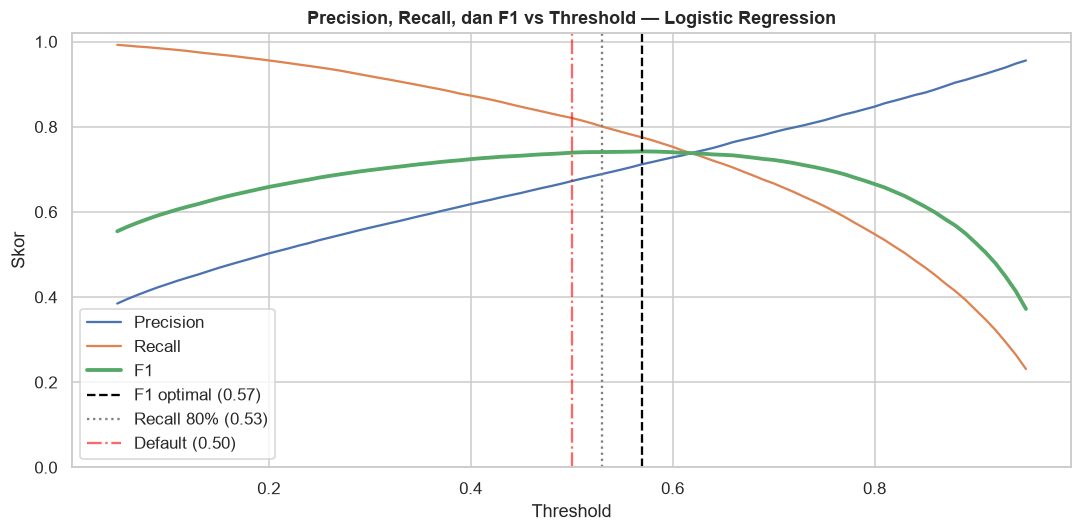

In [16]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(tabel_threshold["Threshold"], tabel_threshold["Precision"], label="Precision")
ax.plot(tabel_threshold["Threshold"], tabel_threshold["Recall"], label="Recall")
ax.plot(tabel_threshold["Threshold"], tabel_threshold["F1"], label="F1", linewidth=2.5)
ax.axvline(thr_f1, color="black", linestyle="--", label=f"F1 optimal ({thr_f1:.2f})")
ax.axvline(thr_recall80, color="gray", linestyle=":", label=f"Recall 80% ({thr_recall80:.2f})")
ax.axvline(0.5, color="red", linestyle="-.", alpha=0.6, label="Default (0.50)")
ax.set_xlabel("Threshold")
ax.set_ylabel("Skor")
ax.set_title(f"Precision, Recall, dan F1 vs Threshold — {nama_terbaik}")
ax.legend(loc="best")
ax.set_ylim(0, 1.02)
plt.tight_layout()
plt.show()

In [17]:
proba_terbaik_test = proba_test_semua[nama_terbaik]

kandidat_threshold = [
    ("0.50 (default)", 0.5),
    (f"{thr_f1:.2f} (F1 optimal)", thr_f1),
    (f"{thr_recall80:.2f} (Recall >= 80%)", thr_recall80),
]

baris_test_thr = []
for label, t in kandidat_threshold:
    m = metrik_lengkap(y_test, proba_terbaik_test, t)
    m["Threshold"] = label
    baris_test_thr.append(m)

tabel_test_thr = pd.DataFrame(baris_test_thr).set_index("Threshold")
display(tabel_test_thr.round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Threshold,,,,,,
0.50 (default),0.8144,0.6731,0.8169,0.7381,0.8991,0.8246
0.57 (F1 optimal),0.8287,0.7145,0.7741,0.7431,0.8991,0.8246
0.53 (Recall >= 80%),0.8212,0.6911,0.7980,0.7407,0.8991,0.8246


**Hasil.** Threshold F1 optimal dari out-of-fold prediction adalah
**0.57**, sedangkan threshold yang menjaga recall minimal 80%
adalah **0.53**. Pada data test:

| Threshold | Accuracy | Precision | Recall | F1 | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|---|
| 0.50 (default) | 0.8144 | 0.6731 | 0.8169 | 0.7381 | 0.8991 | 0.8246 |
| 0.57 (F1 optimal) | 0.8287 | 0.7145 | 0.7741 | 0.7431 | 0.8991 | 0.8246 |
| 0.53 (Recall >= 80%) | 0.8212 | 0.6911 | 0.7980 | 0.7407 | 0.8991 | 0.8246 |

Dengan threshold F1 optimal, model mencapai precision
**0.7145**, recall **0.7741**, dan F1
**0.7431**. Perubahan dari threshold default 0,50 menggeser
trade-off precision–recall, tetapi tidak mengubah kesimpulan utama: model sudah
cukup seimbang untuk dijadikan alat skrining awal.

Untuk aplikasi dipakai threshold **0.57** karena memberi
keseimbangan terbaik antara menangkap mahasiswa berisiko dan membatasi false
positive. Jika kebijakan kampus lebih mengutamakan jangkauan, threshold
0.53 dapat dipakai sebagai alternatif; konsekuensinya,
lebih banyak mahasiswa aman ikut masuk daftar pantauan.

**Trade-off yang perlu dijelaskan.** Menurunkan threshold menaikkan recall (lebih banyak mahasiswa berisiko tertangkap) tetapi menurunkan precision (lebih banyak mahasiswa aman yang ikut ditandai). Untuk sistem early warning, recall biasanya diprioritaskan karena biaya intervensi relatif murah dibanding biaya dropout. Namun, precision tetap penting agar sumber daya bimbingan tidak habis untuk mahasiswa yang sebenarnya aman.

## 8. Confusion Matrix, ROC, dan Precision-Recall Curve

Confusion matrix memakai threshold F1 optimal yang dipilih dari OOF. Kurva ROC dan PR membandingkan ketiga model pada seluruh rentang threshold.

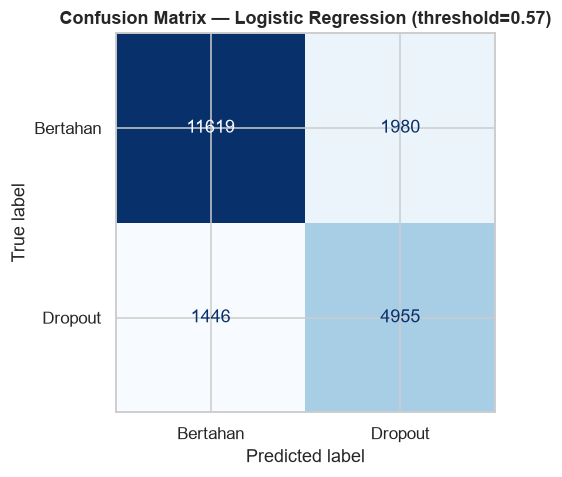

True Negative  (bertahan, benar) : 11,619
False Positive (bertahan, salah) : 1,980
False Negative (dropout, lolos)  : 1,446
True Positive  (dropout, benar)  : 4,955

Recall dropout  : 0.7741
Precision dropout: 0.7145


In [18]:
pred_final = (proba_terbaik_test >= thr_f1).astype(int)
cm = confusion_matrix(y_test, pred_final)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
disp = ConfusionMatrixDisplay(cm, display_labels=["Bertahan", "Dropout"])
disp.plot(cmap="Blues", values_format="d", ax=ax, colorbar=False)
ax.set_title(f"Confusion Matrix — {nama_terbaik} (threshold={thr_f1:.2f})")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True Negative  (bertahan, benar) : {tn:,}")
print(f"False Positive (bertahan, salah) : {fp:,}")
print(f"False Negative (dropout, lolos)  : {fn:,}")
print(f"True Positive  (dropout, benar)  : {tp:,}")
print()
print(f"Recall dropout  : {tp / (tp + fn):.4f}")
print(f"Precision dropout: {tp / (tp + fp):.4f}")

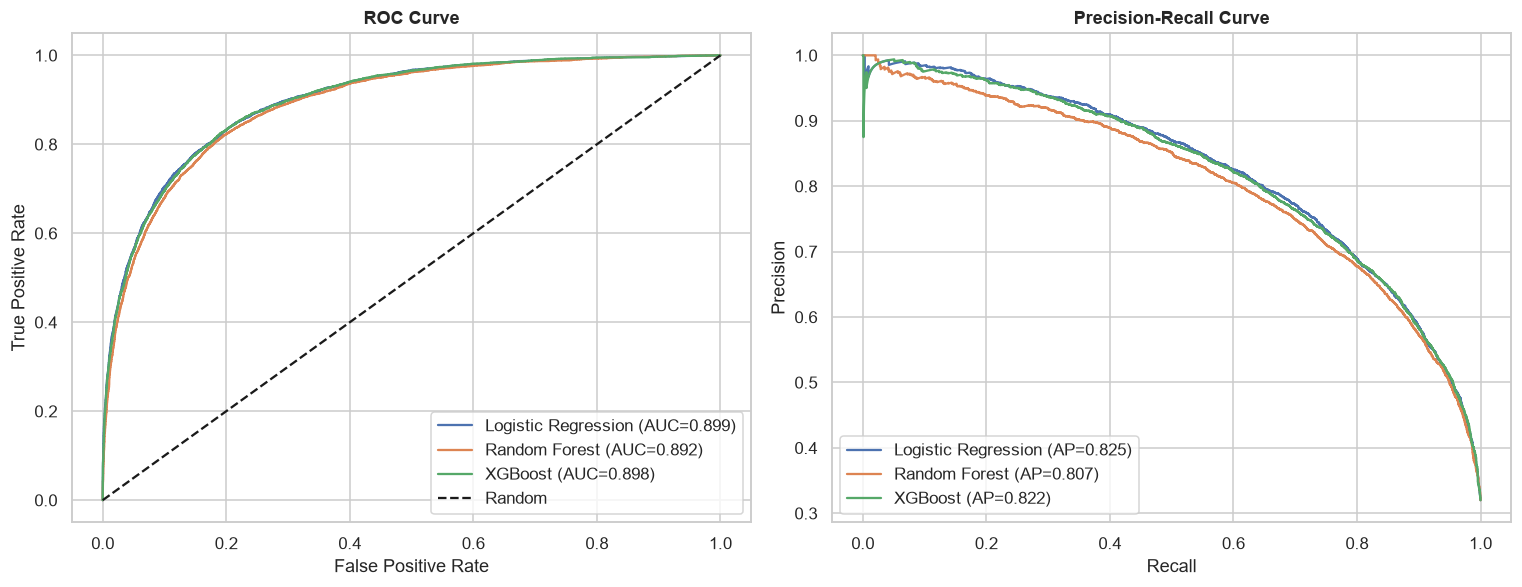

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for nama, proba in proba_test_semua.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    prec, rec, _ = precision_recall_curve(y_test, proba)

    axes[0].plot(fpr, tpr, label=f"{nama} (AUC={roc_auc_score(y_test, proba):.3f})")
    axes[1].plot(rec, prec, label=f"{nama} (AP={average_precision_score(y_test, proba):.3f})")

axes[0].plot([0, 1], [0, 1], "k--", label="Random")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve")
axes[0].legend(loc="lower right")

axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve")
axes[1].legend(loc="lower left")

plt.tight_layout()
plt.show()

**Hasil.** ROC-AUC ketiga model berada di kisaran
0.8916–0.8991, sedangkan PR-AUC
0.8068–0.8246. **XGBoost** unggul
tipis pada kedua kurva.

Kurva ROC memperlihatkan kemampuan diskriminasi di seluruh threshold. Karena kelas
dropout hanya 32%, kurva PR lebih informatif: ia menunjukkan seberapa banyak
prediksi dropout yang benar pada setiap tingkat recall. PR-AUC yang jauh di atas
baseline acak (sekitar 0.32) menandakan model
benar-benar belajar pola, bukan sekadar menebak kelas mayoritas.

Ketiga kurva saling berdekatan, jadi perbedaan performa lebih disebabkan oleh
kalibrasi probabilitas dan bentuk keputusan di sekitar threshold, bukan oleh satu
model yang jauh lebih superior.

**Interpretasi.** ROC-AUC mengukur kemampuan model membedakan kedua kelas di seluruh threshold. PR-AUC lebih informatif ketika kelas positif tidak dominan, karena fokus pada precision dan recall kelas dropout. Model yang baik harus tinggi pada keduanya, bukan hanya salah satu.

## 9. Feature Importance

Bagian ini menjawab pertanyaan: **faktor apa yang paling berpengaruh terhadap risiko dropout?**

- Untuk model berbasis pohon, dipakai `feature_importances_` (kontribusi penurunan impurity).
- Untuk Logistic Regression, dipakai koefisien: **positif menaikkan risiko**, **negatif menurunkan risiko**.

Fitur hasil one-hot diberi nama kategori aslinya agar mudah dibaca.

,Fitur,Nilai
15,gpa_semester_1,-1.2639
45,family_income_level_High,-0.4860
7,tuition_up_to_date,-0.3769
46,family_income_level_Low,0.3461
18,lms_logins_per_week,-0.3128
1,missed_deadlines,0.2912
9,weekly_work_hours,0.2724
16,attendance_rate,-0.2698
20,stress_level,0.2659
14,units_failed,0.2638


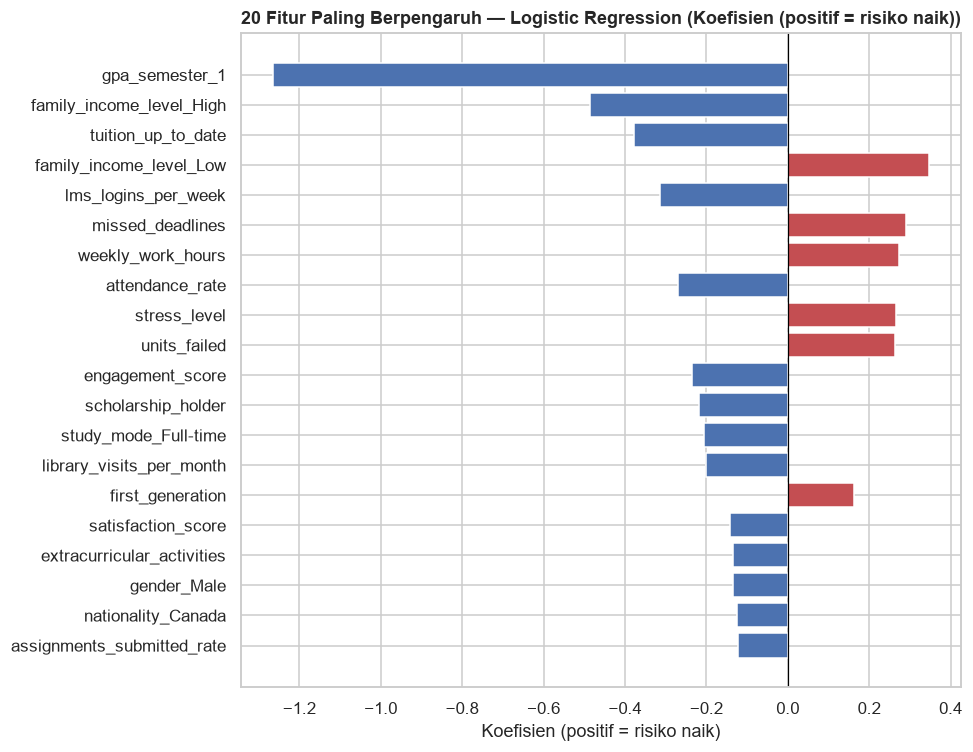

In [20]:
prep_fitted = pipe_terbaik.named_steps["prep"]
model_fitted = pipe_terbaik.named_steps["model"]
fitur_keluar = prep_fitted.get_feature_names_out()

if hasattr(model_fitted, "coef_"):
    nilai = model_fitted.coef_[0]
    label_nilai = "Koefisien (positif = risiko naik)"
    tipe = "koefisien"
else:
    nilai = model_fitted.feature_importances_
    label_nilai = "Feature Importance"
    tipe = "importance"

tabel_imp = pd.DataFrame({"Fitur": fitur_keluar, "Nilai": nilai})
tabel_imp["Fitur"] = tabel_imp["Fitur"].str.replace(
    r"^(skewed|numeric|categorical)__", "", regex=True
)
tabel_imp["Abs"] = tabel_imp["Nilai"].abs()
tabel_imp = tabel_imp.sort_values("Abs", ascending=False).head(20)

display(tabel_imp[["Fitur", "Nilai"]].round(4))

fig, ax = plt.subplots(figsize=(9, 7))
warna = ["#C44E52" if v >= 0 else "#4C72B0" for v in tabel_imp["Nilai"]]
ax.barh(tabel_imp["Fitur"], tabel_imp["Nilai"], color=warna)
ax.invert_yaxis()
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title(f"20 Fitur Paling Berpengaruh — {nama_terbaik} ({label_nilai})")
ax.set_xlabel(label_nilai)
ax.set_ylabel("")
plt.tight_layout()
plt.show()

**Hasil.** Sepuluh fitur paling berpengaruh:

| Peringkat | Fitur | Nilai |
|---|---|---|
| 1 | gpa_semester_1 | -1.2639 |
| 2 | family_income_level_High | -0.4860 |
| 3 | tuition_up_to_date | -0.3769 |
| 4 | family_income_level_Low | 0.3461 |
| 5 | lms_logins_per_week | -0.3128 |
| 6 | missed_deadlines | 0.2912 |
| 7 | weekly_work_hours | 0.2724 |
| 8 | attendance_rate | -0.2698 |
| 9 | stress_level | 0.2659 |
| 10 | units_failed | 0.2638 |

Fitur dengan kontribusi positif terbesar adalah **family_income_level_Low** (0.3461). Fitur dengan kontribusi negatif terbesar adalah **gpa_semester_1** (-1.2639).

Pola ini konsisten dengan EDA: **IPK semester 1** dan **kegagalan mata kuliah**
mendominasi, diikuti indikator keterlibatan seperti tenggat terlewat dan kehadiran.
Fitur turunan `engagement_score` masuk sepuluh besar, sedangkan `fail_rate` dan
`risk_flag_count` kontribusinya lebih kecil karena informasinya sudah sangat
berkorelasi dengan `units_failed`, kehadiran, tenggat, dan IPK. Feature engineering
tetap membantu merangkum sinyal, tetapi tidak otomatis membuat model linear lebih
akurat ketika fitur asalnya sudah tersedia.

Arah hubungan masuk akal secara domain. IPK rendah, banyak mata kuliah gagal, dan
sering melewatkan tenggat menaikkan risiko; kehadiran, pengumpulan tugas, dan
kepuasan belajar menurunkannya. Namun, ini tetap asosiasi prediktif, bukan bukti
kausal.

**Catatan interpretasi.** Feature importance menunjukkan **kontribusi prediktif**, bukan hubungan kausal. Fitur yang penting belum tentu menjadi penyebab dropout; bisa jadi ia berkorelasi dengan penyebab lain. Arah koefisien Logistic Regression juga dipengaruhi korelasi antarfitur, sehingga tafsirannya harus hati-hati.

## 10. Analisis Kesalahan Prediksi

Tidak cukup hanya melaporkan metrik. Bagian ini membandingkan karakteristik **True Positive, False Negative, False Positive, dan True Negative** untuk memahami di mana model gagal.

Fokus utama: **False Negative** — mahasiswa yang benar-benar dropout tetapi diprediksi bertahan.

In [21]:
df_error = X_test.copy()
df_error["y_true"] = y_test.values
df_error["y_pred"] = pred_final
df_error["proba"] = proba_terbaik_test

df_error["kelompok"] = np.select(
    [
        (df_error["y_true"] == 1) & (df_error["y_pred"] == 1),
        (df_error["y_true"] == 1) & (df_error["y_pred"] == 0),
        (df_error["y_true"] == 0) & (df_error["y_pred"] == 1),
    ],
    ["True Positive", "False Negative", "False Positive"],
    default="True Negative",
)

urutan = ["True Positive", "False Negative", "False Positive", "True Negative"]
ringkasan_error = (
    df_error.groupby("kelompok")
    .agg(
        Jumlah=("y_true", "size"),
        GPA_Sem1=("gpa_semester_1", "mean"),
        Units_Failed=("units_failed", "mean"),
        Attendance=("attendance_rate", "mean"),
        Missed_Deadlines=("missed_deadlines", "mean"),
        Probabilitas=("proba", "mean"),
    )
    .reindex(urutan)
)
display(ringkasan_error.round(2))

,Jumlah,GPA_Sem1,Units_Failed,Attendance,Missed_Deadlines,Probabilitas
kelompok,,,,,,
True Positive,4955,1.71,4.77,65.57,3.78,0.86
False Negative,1446,2.61,2.54,75.23,2.25,0.35
False Positive,1980,2.07,3.86,69.00,3.09,0.74
True Negative,11619,3.03,1.68,80.03,1.69,0.17


In [22]:
print("Contoh 10 False Negative (dropout yang lolos prediksi):")
display(
    df_error[df_error["kelompok"] == "False Negative"][[
        "gpa_semester_1", "units_failed", "attendance_rate",
        "missed_deadlines", "proba",
    ]].head(10).round(3)
)

print("\nContoh 10 False Positive (bertahan yang ditandai berisiko):")
display(
    df_error[df_error["kelompok"] == "False Positive"][[
        "gpa_semester_1", "units_failed", "attendance_rate",
        "missed_deadlines", "proba",
    ]].head(10).round(3)
)

Contoh 10 False Negative (dropout yang lolos prediksi):


,gpa_semester_1,units_failed,attendance_rate,missed_deadlines,proba
86957,3.16,0,57.5,2,0.367
99382,2.44,3,65.7,3,0.398
65594,2.38,2,85.8,1,0.237
19922,2.99,1,43.9,3,0.223
54459,3.11,2,76.8,0,0.569
42531,2.65,1,37.3,0,0.458
24173,3.26,0,56.5,9,0.224
98870,2.52,5,52.0,1,0.363
30183,3.37,1,49.8,0,0.248
93647,2.09,5,100.0,2,0.464



Contoh 10 False Positive (bertahan yang ditandai berisiko):


,gpa_semester_1,units_failed,attendance_rate,missed_deadlines,proba
18004,2.15,2,51.2,3,0.652
8055,2.04,3,97.6,7,0.588
75403,2.16,2,43.7,1,0.899
56981,1.89,6,100.0,7,0.675
92151,2.52,1,60.6,3,0.668
37525,2.11,4,98.1,4,0.623
75223,2.23,2,43.4,8,0.822
33171,1.75,5,84.0,1,0.579
16513,1.41,6,93.1,3,0.949
92340,2.23,5,83.5,4,0.776


**Hasil.** Dari 6,401 mahasiswa yang benar-benar dropout,
model menangkap **4,955** (true positive) dan melewatkan **1,446** (false
negative). Dari 13,599 mahasiswa yang bertahan, model salah menandai
**1,980** sebagai berisiko (false positive).

| Kelompok | Jumlah | GPA_Sem1 | Units_Failed | Attendance | Missed_Deadlines | Probabilitas |
|---|---|---|---|---|---|---|
| True Positive | 4955.0000 | 1.7100 | 4.7700 | 65.5700 | 3.7800 | 0.8600 |
| False Negative | 1446.0000 | 2.6100 | 2.5400 | 75.2300 | 2.2500 | 0.3500 |
| False Positive | 1980.0000 | 2.0700 | 3.8600 | 69.0000 | 3.0900 | 0.7400 |
| True Negative | 11619.0000 | 3.0300 | 1.6800 | 80.0300 | 1.6900 | 0.1700 |

False negative memiliki rata-rata IPK **2.61**, lebih tinggi dibanding true positive (1.71), dengan kehadiran 75.2% yang juga lebih tinggi. Artinya, ada mahasiswa yang secara akademik tampak menengah tetapi tetap dropout; sinyalnya mungkin berada di luar fitur yang tersedia.

False positive juga perlu dibaca dengan konteks: mereka bisa memiliki satu-dua
indikator risiko yang menonjol tetapi tetap bertahan. Untuk aplikasi, kelompok ini
tidak otomatis dianggap pasti dropout; mereka bisa diberi intervensi ringan berupa
pengecekan atau penawaran bantuan. Sebaliknya, false negative adalah kelompok yang
paling mahal karena tidak mendapat kesempatan intervensi. Karena itu, recall tetap
menjadi metrik utama, dengan precision sebagai penyeimbang agar daftar prioritas
tidak terlalu penuh.

**Interpretasi.** False negative biasanya berasal dari mahasiswa yang secara akademik tidak terlalu buruk (GPA dan kehadiran masih menengah), sehingga model memberi probabilitas di bawah threshold. Ini menunjukkan keterbatasan data: faktor di luar dataset (motivasi, kondisi keluarga, kesehatan mental, perubahan status ekonomi) tidak terukur.

Sebaliknya, false positive sering berasal dari mahasiswa dengan satu-dua indikator risiko yang menonjol tetapi tetap bertahan. Untuk aplikasi, kelompok ini tidak boleh diabaikan sepenuhnya: mereka bisa diberi intervensi ringan berupa pengecekan, bukan langsung dianggap pasti dropout.

## 11. Pemeriksaan Overfitting

Model yang terlalu baik pada data training tetapi jauh lebih buruk pada data test mengindikasikan overfitting. Perbandingan dilakukan pada threshold yang sama.

In [23]:
proba_train = pipe_terbaik.predict_proba(X_train)[:, 1]
pred_train = (proba_train >= thr_f1).astype(int)

tabel_fit = pd.DataFrame({
    "Train": metrik_lengkap(y_train, proba_train, thr_f1),
    "Test": metrik_lengkap(y_test, proba_terbaik_test, thr_f1),
}).T

# Tambahkan baris gap, bukan kolom, agar mudah dibaca
tabel_fit.loc["Gap (Train - Test)"] = tabel_fit.loc["Train"] - tabel_fit.loc["Test"]
display(tabel_fit.round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Train,0.8283,0.7128,0.7762,0.7431,0.9000,0.8247
Test,0.8287,0.7145,0.7741,0.7431,0.8991,0.8246
Gap (Train - Test),-0.0004,-0.0017,0.0021,0.0000,0.0009,0.0001


**Hasil.** Pada threshold yang sama, model terpilih memiliki:

| Data | Accuracy | Precision | Recall | F1 | ROC-AUC | PR-AUC |
|---|---|---|---|---|---|---|
| Train | 0.8283 | 0.7128 | 0.7762 | 0.7431 | 0.9000 | 0.8247 |
| Test | 0.8287 | 0.7145 | 0.7741 | 0.7431 | 0.8991 | 0.8246 |
| Gap (Train - Test) | -0.0004 | -0.0017 | 0.0021 | 0.0000 | 0.0009 | 0.0001 |

Gap F1 di bawah 0,03 menunjukkan model **tidak overfit berat**. Performa pada data test hampir setara dengan data training.

Gap pada accuracy -0.0004, precision -0.0017,
recall +0.0021, dan ROC-AUC +0.0009. Pola gap perlu
dibaca per metrik: model bisa tampak jauh lebih baik pada accuracy karena kelas
mayoritas, sementara selisih recall hanya kecil. Yang penting adalah apakah
kemampuan mendeteksi dropout pada data baru tetap terjaga, bukan apakah model
menghafal data training.

**Interpretasi.** Gap yang kecil (di bawah ~0,03–0,05) menunjukkan model tidak overfit berat. Gap besar pada accuracy tetapi kecil pada recall/F1 perlu dibaca hati-hati: bisa jadi model hanya kesulitan pada sebagian kecil kasus, bukan menghafal data training.

## 12. Menyimpan Model untuk Aplikasi

Model terbaik, threshold, daftar fitur, dan metrik disimpan agar aplikasi Streamlit dapat memuat konfigurasi yang persis sama dengan saat evaluasi. Menyimpan hanya model tanpa threshold berisiko membuat aplikasi memakai ambang yang berbeda.

In [24]:
MODEL_DIR = Path("../models")
REPORT_DIR = Path("../reports")
MODEL_DIR.mkdir(exist_ok=True)
REPORT_DIR.mkdir(exist_ok=True)

label_thr_f1 = f"{thr_f1:.2f} (F1 optimal)"

artefak = {
    "model": pipe_terbaik,
    "nama_model": nama_terbaik,
    "threshold": thr_f1,
    "threshold_recall80": thr_recall80,
    "features": list(X.columns),
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "metrics_test_default": tabel_test.loc[nama_terbaik].to_dict(),
    "metrics_test_threshold": tabel_test_thr.loc[label_thr_f1].to_dict(),
}

joblib.dump(artefak, MODEL_DIR / "model_dropout.pkl")

tabel_baseline.round(4).to_csv(REPORT_DIR / "perbandingan_model_cv.csv")
tabel_test.round(4).to_csv(REPORT_DIR / "perbandingan_model_test.csv")
tabel_test_thr.round(4).to_csv(REPORT_DIR / "perbandingan_threshold.csv")

ringkasan = {
    "nama_model": nama_terbaik,
    "n_train": int(X_train.shape[0]),
    "n_test": int(X_test.shape[0]),
    "n_fitur": int(X.shape[1]),
    "baseline_cv": tabel_baseline.round(4).to_dict(orient="index"),
    "baseline_cv_std": tabel_baseline_std.round(4).to_dict(orient="index"),
    "tuning": {
        r["Model"]: {
            "f1_cv": round(float(r["F1 CV terbaik"]), 4),
            "params": {k.replace("model__", ""): v for k, v in r["Parameter terbaik"].items()},
        }
        for r in tuning_rows
    },
    "test_default": tabel_test.round(4).to_dict(orient="index"),
    "threshold_f1": round(float(thr_f1), 4),
    "threshold_recall80": round(float(thr_recall80), 4),
    "test_threshold": tabel_test_thr.round(4).to_dict(orient="index"),
    "confusion_matrix": {
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    },
    "top_features": tabel_imp[["Fitur", "Nilai"]].round(4).to_dict(orient="records"),
    "fit": tabel_fit.round(4).to_dict(orient="index"),
    "error_groups": ringkasan_error.round(2).to_dict(orient="index"),
}

with open(REPORT_DIR / "ringkasan_model.json", "w", encoding="utf-8") as f:
    json.dump(ringkasan, f, ensure_ascii=False, indent=2, default=float)

print("Model disimpan di :", (MODEL_DIR / "model_dropout.pkl").resolve())
print("Laporan disimpan di:", REPORT_DIR.resolve())
print()
print("Isi artefak:")
for k, v in artefak.items():
    if k == "model":
        print(f"  {k:<26}: {type(v).__name__}")
    elif isinstance(v, (list, dict)) and k not in ("metrics_test_default", "metrics_test_threshold"):
        print(f"  {k:<26}: {len(v) if isinstance(v, list) else 'dict'}")
    else:
        print(f"  {k:<26}: {v}")

Model disimpan di : C:\!Documents\project-ml-kel-2\models\model_dropout.pkl
Laporan disimpan di: C:\!Documents\project-ml-kel-2\reports

Isi artefak:
  model                     : Pipeline
  nama_model                : Logistic Regression
  threshold                 : 0.5700000000000002
  threshold_recall80        : 0.5300000000000001
  features                  : 32
  numeric_features          : 27
  categorical_features      : 5
  metrics_test_default      : {'Accuracy': 0.81445, 'Precision': 0.6731462409886715, 'Recall': 0.8169036088111232, 'F1': 0.7380901969087444, 'ROC-AUC': 0.89910600110177, 'PR-AUC': 0.8246071089770592}
  metrics_test_threshold    : {'Accuracy': 0.8287, 'Precision': 0.7144917087238645, 'Recall': 0.7740977972191845, 'F1': 0.7431013797240552, 'ROC-AUC': 0.89910600110177, 'PR-AUC': 0.8246071089770592}


## 13. Kesimpulan dan Analisis

**Model terpilih: Logistic Regression.** Pemilihan didasarkan pada F1
cross-validation hasil tuning, bukan pada skor test. Pada holdout test dengan
threshold 0.57, model mencapai:

- **F1** 0.7431
- **Recall dropout** 0.7741
- **Precision dropout** 0.7145
- **ROC-AUC** 0.8991
- **PR-AUC** 0.8246

Dari 6,401 mahasiswa dropout di data test, **4,955** berhasil
ditangkap dan **1,446** terlewat. Model juga menandai **1,980** mahasiswa
yang sebenarnya bertahan, sehingga hasilnya harus dipakai sebagai daftar prioritas
untuk pengecekan manusia, bukan vonis otomatis.

**Model terbaik vs terendah.** XGBoost memiliki F1 test tertinggi
(0.7390), sedangkan Random Forest terendah
(0.7317). Selisihnya kecil, sehingga pemilihan akhir juga
mempertimbangkan stabilitas CV dan kemudahan interpretasi. Logistic Regression dipilih
karena konsisten kuat pada CV dan memberikan trade-off precision–recall yang wajar.

**Faktor utama.** Tiga fitur teratas adalah gpa_semester_1, family_income_level_High, tuition_up_to_date. Temuan ini sejalan dengan EDA:
masalah akademik pada semester 1 adalah sinyal risiko yang paling kuat, diikuti
keterlibatan belajar. Faktor di luar dataset — motivasi, kondisi keluarga,
kesehatan mental, dan perubahan status ekonomi — kemungkinan menjelaskan sebagian
false negative yang tersisa.

**Implikasi.** Model dapat dipakai di awal semester 2 untuk menyaring mahasiswa
yang perlu dihubungi lebih dulu. Ambang keputusan dapat disesuaikan dengan kapasitas
layanan bimbingan: threshold lebih rendah untuk jangkauan lebih luas, threshold
lebih tinggi untuk intervensi yang lebih terarah.

### Keterbatasan

1. **Indikasi data sintetis.** Pola `gpa_semester_2 < gpa_semester_1` pada 90,4% baris tidak lazim. Hasil tidak boleh digeneralisasi ke populasi mahasiswa nyata tanpa validasi ulang.
2. **Asumsi timing.** Fitur keterlibatan (`attendance_rate`, `assignments_submitted_rate`, `lms_logins_per_week`, `library_visits_per_month`, `missed_deadlines`) dianggap merekam semester 1. Dataset tidak mendokumentasikan periode pengukuran.
3. **Tidak ada validasi temporal.** Split dilakukan secara acak, bukan berdasarkan angkatan atau waktu. Model belum diuji pada data tahun berikutnya.
4. **Fitur psikologis terbatas.** `stress_level`, `satisfaction_score`, dan `mental_health_support` kemungkinan disederhanakan; faktor sosial yang lebih kaya tidak tersedia.
5. **Threshold dipilih dari OOF train.** Meskipun data test bersih, threshold masih bergantung pada distribusi data training.

### Potensi pengembangan

1. **Validasi temporal** antar-angkatan untuk menguji stabilitas model.
2. **SHAP** untuk interpretasi per mahasiswa, bukan hanya global.
3. **Cost-sensitive learning** dengan biaya false negative dan false positive yang eksplisit.
4. **Survival analysis** untuk memperkirakan waktu dropout, bukan hanya ya/tidak.
5. **Aplikasi batch** untuk mengunggah CSV seluruh angkatan dan menghasilkan daftar prioritas intervensi.
6. **Monitoring drift** ketika data semester baru masuk.

### Langkah berikutnya

Model dan threshold siap dipakai di `app.py` (Streamlit). Aplikasi akan memuat `models/model_dropout.pkl`, menerima input profil mahasiswa, dan menampilkan probabilitas serta kategori risiko.